# Data VZP: přechody mezi segmenty

Kam se žena posune mezi dvěma po sobě jdoucími pozvánkami? Segmenty podle `config/segments_vzp_v2.yaml`
(11 segmentů, viz `vzp_segmentation.ipynb`, oddíl 7).

**Jak vznikají přechody.** Žena, která do 12 měsíců nepřijde, dostane další dopis zhruba za rok;
žena, která přijde, dostane další dopis až po 36 a více měsících, tedy většinou už mimo okno dat
2020–2024. Proto:
* stav po pozvánce je buď **„přišla do 12 měsíců“**, nebo **segment další pozvánky**, nebo
  **„nepřišla, další pozvánka v datech není“**;
* přechodovou matici počítáme jen z pozvánek 2020–2023 (u nich je další pozvánka pozorovatelná);
* dlouhodobý pohled dávají **kohorty roku 2020**: kolik žen z každého segmentu přišlo do konce roku
  2024 po kterékoli pozvánce.

Notebook ukazuje jen agregáty.

## Hlavní zjištění

1. **Segmenty se mění hlavně u žen, které nechodí.** Kdo do 12 měsíců nepřijde, dostane další dopis
   zhruba za rok (92 %); kdo přijde, dostane další až po 3 a více letech (v datech jen 14 %).
2. **Segmenty bez screeningu jsou „lepkavé“.** Z žen, které nepřijdou a jsou pozvané znovu, zůstává
   ve stejném segmentu 56–83 %, nejvíc opakovaně nereagující (83 %). Přesun do lepšího segmentu je
   vzácný (z odpojených ke gynekologovi 1 %).
3. **Cesta dolů vede přes počet pozvánek.** Ženy zvané málokrát přecházejí po 7. pozvánce do
   „opakovaně nereaguje“ (z gynekologa 9 %, z jiné prevence 15 % ročně).
4. **První pozvánka rozhoduje.** Z žen s první pozvánkou v roce 2020 přišlo 48 % hned a do páté
   pozvánky celkem 75 %. Kdo napoprvé nepřijde, většinou zůstane v segmentech bez screeningu.
5. **Každý další dopis přináší méně.** U žen u gynekologa zvaných málokrát přijde na první dopis
   25 %, z dosud nepřišlých pak 15, 12, 10 a 8 %. U opakovaně nereagujících a odpojených je výnos
   stále jen 2–3 % na dopis.
6. **Za pět let (kohorty 2020):** z první pozvánky v kontaktu se zdravotnictvím přišlo 80 % žen,
   z opakovaně nereagujících a odpojených jen 12–13 %.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_segment_transitions"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

Y = "SCREENING_12M_FLAG"
d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in ["FIRST_INVITATION", Y]:
    d[c] = (d[c] == "A").astype(int)
d["BEZ_SCREENINGU"] = d.MONTHS_SINCE_LAST_SCREEN.isna().astype(int)
d["PREVENCE"] = ((d.OTHER_SCREENING_36M_CNT >= 1) | (d.DENTAL_PREVENTION_24M_CNT >= 1)
                 | (d.GP_PREVENTION_24M_CNT >= 1)).astype(int)

SEG = yaml.safe_load(open(BASE / "config" / "segments_vzp_v2.yaml", encoding="utf-8"))["segments"]
NAZEV = {s["id"]: s["name_cs"] for s in SEG}
PORADI = [s["id"] for s in SEG]
seg = pd.Series(pd.NA, index=d.index, dtype="object")
for s in SEG:
    m = d.eval(s["rule"])
    if np.isscalar(m):
        m = pd.Series(bool(m), index=d.index)
    seg[seg.isna() & m.astype(bool)] = s["id"]
assert seg.notna().all()
d["SEG"] = seg.map(NAZEV)

d = d.sort_values(["PERSON_ID", "INVITATION_DATE"]).reset_index(drop=True)
g = d.groupby("PERSON_ID")
d["SEG_DALSI"] = g.SEG.shift(-1)
d["MESICU_DO_DALSI"] = (g.INVITATION_DATE.shift(-1) - d.INVITATION_DATE).dt.days / 30.44
d["ROK"] = d.INVITATION_DATE.dt.year
NAZVY = [NAZEV[s] for s in PORADI]
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen")

1,344,556 pozvánek · 508,527 žen


## 1 · Jak se zve znovu

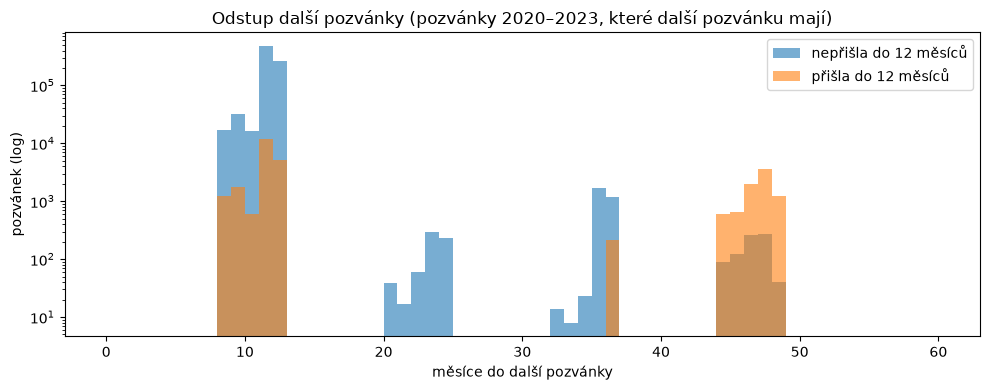

,pozvánek 2020–2023,má další pozvánku v datech,medián měsíců do další
SCREENING_12M_FLAG,,,
nepřišla do 12 měsíců,"877,819",92.0%,11.9
přišla do 12 měsíců,"210,271",13.7%,12.0


In [2]:
r = d[d.ROK <= 2023]
ZNOVU = pd.DataFrame({
    "pozvánek 2020–2023": r.groupby(Y).size(),
    "má další pozvánku v datech": r.groupby(Y).SEG_DALSI.apply(lambda x: x.notna().mean()),
    "medián měsíců do další": r.groupby(Y).MESICU_DO_DALSI.median(),
}).rename(index={0: "nepřišla do 12 měsíců", 1: "přišla do 12 měsíců"})
ZNOVU.to_csv(OUT / "znovu_zvani.csv")

fig, ax = plt.subplots(figsize=(10, 4))
for v, lab in [(0, "nepřišla do 12 měsíců"), (1, "přišla do 12 měsíců")]:
    ax.hist(r.loc[r[Y] == v, "MESICU_DO_DALSI"].dropna(), bins=range(0, 61), alpha=0.6, label=lab)
ax.set_yscale("log"); ax.set_xlabel("měsíce do další pozvánky"); ax.set_ylabel("pozvánek (log)")
ax.set_title("Odstup další pozvánky (pozvánky 2020–2023, které další pozvánku mají)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "odstup_dalsi_pozvanky.png", dpi=120); plt.show()
ZNOVU.style.format({"pozvánek 2020–2023": "{:,}", "má další pozvánku v datech": "{:.1%}",
                    "medián měsíců do další": "{:.1f}"})

## 2 · Přechodová matice (pozvánky 2020–2023)

Řádek = segment při pozvánce, sloupec = co následovalo: přišla do 12 měsíců, nebo segment další
pozvánky, nebo konec (nepřišla a další pozvánka v datech není). Řádky dávají 100 %.

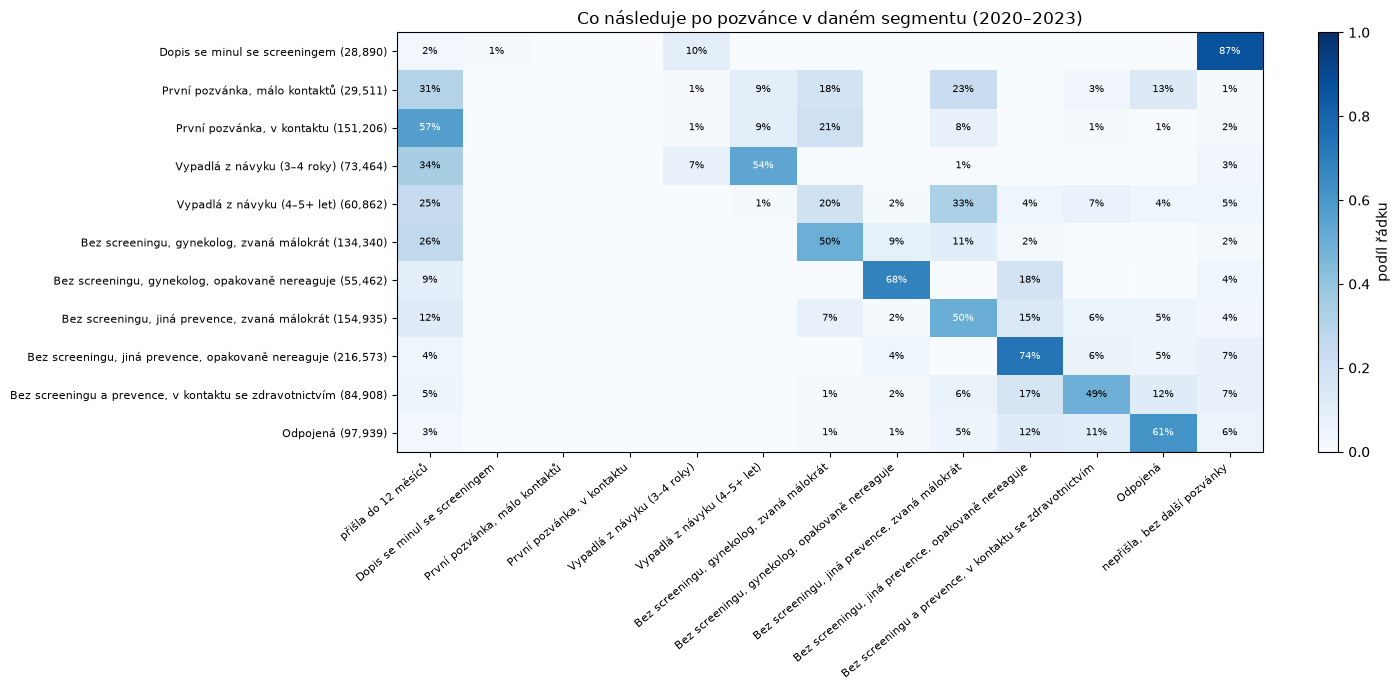

In [3]:
r = d[d.ROK <= 2023].copy()
r["DALE"] = np.where(r[Y] == 1, "přišla do 12 měsíců",
                     np.where(r.SEG_DALSI.notna(), r.SEG_DALSI, "nepřišla, bez další pozvánky"))
SLOUPCE = ["přišla do 12 měsíců"] + NAZVY + ["nepřišla, bez další pozvánky"]
CNT = pd.crosstab(r.SEG, r.DALE).reindex(index=NAZVY, columns=SLOUPCE, fill_value=0)
MAT = CNT.div(CNT.sum(axis=1), axis=0)
CNT.to_csv(OUT / "prechody_pocty.csv"); MAT.round(4).to_csv(OUT / "prechody_podily.csv")

fig, ax = plt.subplots(figsize=(15, 7))
im = ax.imshow(MAT.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SLOUPCE))); ax.set_xticklabels(SLOUPCE, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(NAZVY))); ax.set_yticklabels([f"{n} ({CNT.loc[n].sum():,})" for n in NAZVY], fontsize=8)
for i in range(MAT.shape[0]):
    for j in range(MAT.shape[1]):
        v = MAT.iat[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
plt.colorbar(im, ax=ax, label="podíl řádku")
ax.set_title("Co následuje po pozvánce v daném segmentu (2020–2023)")
plt.tight_layout(); plt.savefig(OUT / "prechodova_matice.png", dpi=120); plt.show()

### Jen ženy, které nepřišly

Stejná matice podmíněná tím, že žena do 12 měsíců nepřišla a dostala další pozvánku: kam se
přesune? Diagonála = zůstala ve stejném segmentu.

In [4]:
n = r[(r[Y] == 0) & r.SEG_DALSI.notna()]
CN = pd.crosstab(n.SEG, n.SEG_DALSI).reindex(index=NAZVY, columns=NAZVY, fill_value=0)
MN = CN.div(CN.sum(axis=1), axis=0).fillna(0)
MN.round(4).to_csv(OUT / "prechody_nepriste.csv")
mimo = MN.where(~np.eye(len(NAZVY), dtype=bool), -1)
ZUST = pd.DataFrame({"nepřišlo a zvaná znovu": CN.sum(axis=1), "zůstala ve stejném segmentu": np.diag(MN),
                     "nejčastější jiný cíl": mimo.idxmax(axis=1), "jeho podíl": mimo.max(axis=1)})
ZUST.to_csv(OUT / "setrvani.csv")
ZUST.style.format({"nepřišlo a zvaná znovu": "{:,}", "zůstala ve stejném segmentu": "{:.0%}", "jeho podíl": "{:.0%}"})

,nepřišlo a zvaná znovu,zůstala ve stejném segmentu,nejčastější jiný cíl,jeho podíl
SEG,,,,
Dopis se minul se screeningem,"3,121",9%,Vypadlá z návyku (3–4 roky),91%
"První pozvánka, málo kontaktů","20,070",0%,"Bez screeningu, jiná prevence, zvaná málokrát",33%
"První pozvánka, v kontaktu","62,150",0%,"Bez screeningu, gynekolog, zvaná málokrát",51%
Vypadlá z návyku (3–4 roky),"45,840",11%,Vypadlá z návyku (4–5+ let),86%
Vypadlá z návyku (4–5+ let),"42,977",2%,"Bez screeningu, jiná prevence, zvaná málokrát",47%
"Bez screeningu, gynekolog, zvaná málokrát","96,615",69%,"Bez screeningu, jiná prevence, zvaná málokrát",15%
"Bez screeningu, gynekolog, opakovaně nereaguje","48,228",78%,"Bez screeningu, jiná prevence, opakovaně nereaguje",21%
"Bez screeningu, jiná prevence, zvaná málokrát","131,152",59%,"Bez screeningu, jiná prevence, opakovaně nereaguje",17%
"Bez screeningu, jiná prevence, opakovaně nereaguje","192,796",83%,"Bez screeningu a prevence, v kontaktu se zdravotnictvím",7%


## 3 · Dlouhodobě: kohorty roku 2020

Ženy pozvané v roce 2020 podle segmentu při té pozvánce. Sledujeme všechny jejich pozvánky do konce
roku 2024: kolik z nich přišlo aspoň jednou (do 12 měsíců po kterékoli pozvánce) a po kolikáté
pozvánce. Ženy, které nepřijdou, jsou zvané každý rok, takže okna 12 měsíců pokrývají celé období.

C:\Users\vittu\AppData\Local\Temp\ipykernel_12252\2026254089.py:18: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(range(1, 6), row[[f"přišla do {j}. pozvánky" for j in range(1, 6)]].values, "-o", color=f"C{i % 10}",
C:\Users\vittu\AppData\Local\Temp\ipykernel_12252\2026254089.py:18: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(range(1, 6), row[[f"přišla do {j}. pozvánky" for j in range(1, 6)]].values, "-o", color=f"C{i % 10}",
C:\Users\vittu\AppData\Local\Temp\ipykernel_12252\2026254089.py:18: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(range(1, 6), row[[f"přišla do {j}. pozvánky" for j in r

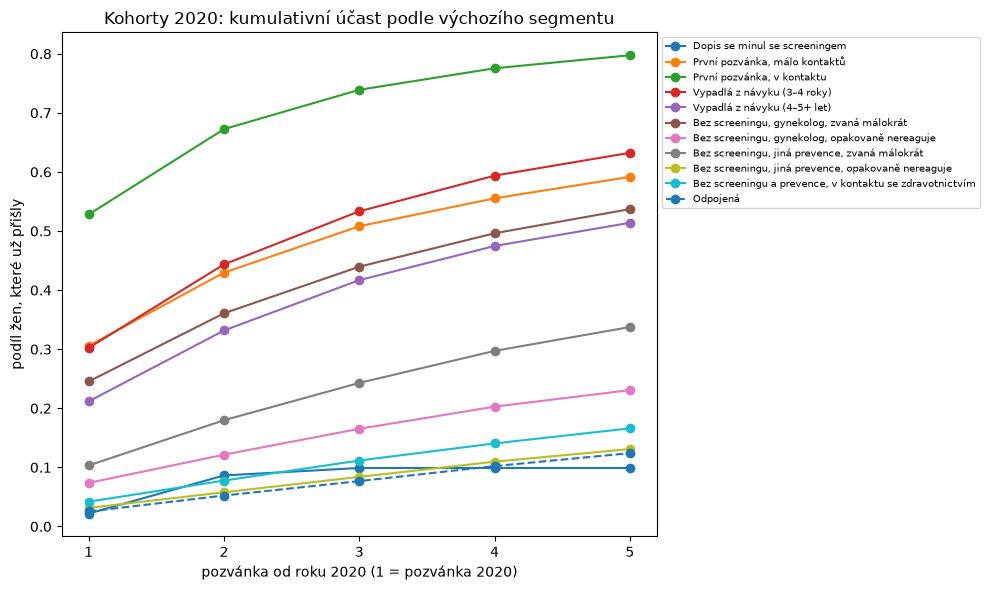

,žen,přišla do 1. pozvánky,přišla do 2. pozvánky,přišla do 3. pozvánky,přišla do 4. pozvánky,přišla do 5. pozvánky,nepřišla do konce 2024,průměr pozvánek 2020–2024
SEG_2020,,,,,,,,
Dopis se minul se screeningem,"6,089",2.2%,8.6%,9.9%,9.9%,9.9%,90.1%,1.2
"První pozvánka, málo kontaktů","9,945",30.6%,43.0%,50.8%,55.5%,59.2%,40.8%,3.2
"První pozvánka, v kontaktu","37,268",52.8%,67.2%,73.9%,77.5%,79.7%,20.3%,2.3
Vypadlá z návyku (3–4 roky),"17,278",30.2%,44.4%,53.3%,59.4%,63.2%,36.8%,3.0
Vypadlá z návyku (4–5+ let),"14,953",21.2%,33.2%,41.7%,47.5%,51.4%,48.6%,3.3
"Bez screeningu, gynekolog, zvaná málokrát","32,842",24.5%,36.1%,44.0%,49.6%,53.7%,46.3%,3.4
"Bez screeningu, gynekolog, opakovaně nereaguje","11,160",7.4%,12.2%,16.5%,20.3%,23.1%,76.9%,4.1
"Bez screeningu, jiná prevence, zvaná málokrát","41,484",10.3%,18.0%,24.3%,29.7%,33.8%,66.2%,3.9
"Bez screeningu, jiná prevence, opakovaně nereaguje","51,911",3.1%,5.8%,8.4%,11.0%,13.1%,86.9%,4.1


In [5]:
k = d[d.ROK == 2020].groupby("PERSON_ID").SEG.first().rename("SEG_2020")
f = d[d.ROK >= 2020].merge(k, left_on="PERSON_ID", right_index=True)
f["poradi"] = f.groupby("PERSON_ID").cumcount() + 1
prvni = f[f[Y] == 1].groupby("PERSON_ID").poradi.min()
z = k.to_frame().join(prvni.rename("prisla_po"))
z["pozvánek 2020–2024"] = f.groupby("PERSON_ID").size()

KOH = pd.DataFrame({"žen": z.groupby("SEG_2020").size()})
for j in range(1, 6):
    KOH[f"přišla do {j}. pozvánky"] = z.groupby("SEG_2020").prisla_po.apply(lambda x: (x <= j).mean())
KOH["nepřišla do konce 2024"] = 1 - z.groupby("SEG_2020").prisla_po.apply(lambda x: x.notna().mean())
KOH["průměr pozvánek 2020–2024"] = z.groupby("SEG_2020")["pozvánek 2020–2024"].mean()
KOH = KOH.reindex(NAZVY)
KOH.to_csv(OUT / "kohorty_2020.csv")

fig, ax = plt.subplots(figsize=(10, 6))
for i, (nm, row) in enumerate(KOH.iterrows()):
    ax.plot(range(1, 6), row[[f"přišla do {j}. pozvánky" for j in range(1, 6)]].values, "-o", color=f"C{i % 10}",
            ls="-" if i < 10 else "--", label=nm)
ax.set_xticks(range(1, 6)); ax.set_xlabel("pozvánka od roku 2020 (1 = pozvánka 2020)")
ax.set_ylabel("podíl žen, které už přišly"); ax.set_title("Kohorty 2020: kumulativní účast podle výchozího segmentu")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(OUT / "kohorty_2020.png", dpi=120); plt.show()
KOH.style.format({"žen": "{:,}", "průměr pozvánek 2020–2024": "{:.1f}",
                  **{c: "{:.1%}" for c in KOH.columns if c.startswith(("přišla", "nepřišla"))}})

### Kam se dostanou ženy z první pozvánky

Ženy s první pozvánkou v roce 2020 a jejich stav při každé další pozvánce (podíl z celé kohorty):
přišla už dřív, je ve kterém segmentu, nebo už další pozvánku nemá.

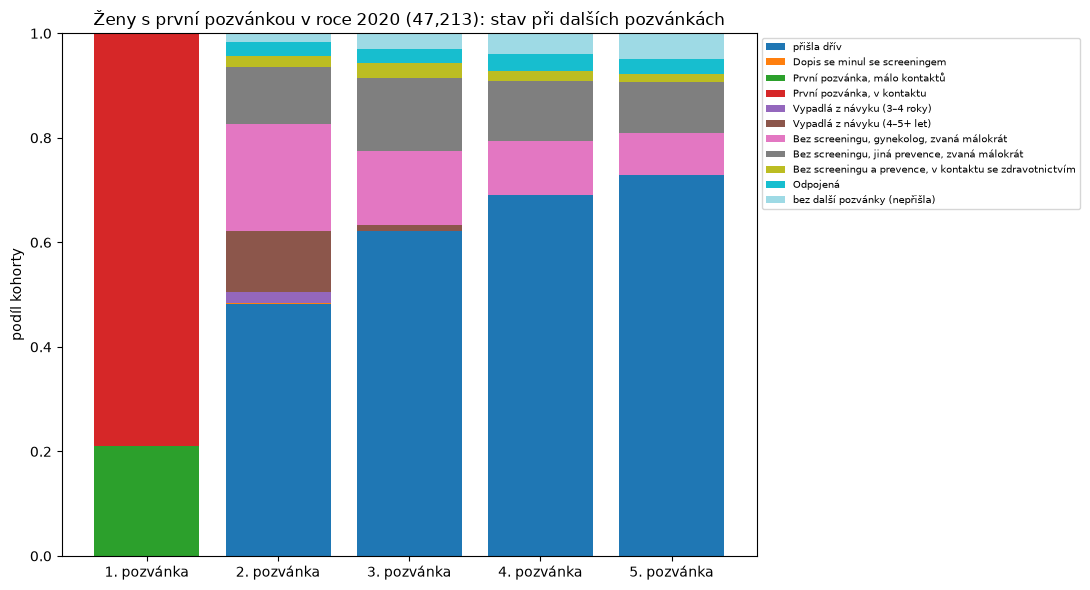

,1. pozvánka,2. pozvánka,3. pozvánka,4. pozvánka,5. pozvánka
SEG,,,,,
přišla dřív,0.0%,48.1%,62.1%,69.0%,72.9%
Dopis se minul se screeningem,0.0%,0.2%,0.0%,0.0%,0.0%
"První pozvánka, málo kontaktů",21.1%,0.0%,0.0%,0.0%,0.0%
"První pozvánka, v kontaktu",78.9%,0.0%,0.0%,0.0%,0.0%
Vypadlá z návyku (3–4 roky),0.0%,2.1%,0.0%,0.0%,0.0%
Vypadlá z návyku (4–5+ let),0.0%,11.8%,1.2%,0.0%,0.0%
"Bez screeningu, gynekolog, zvaná málokrát",0.0%,20.5%,14.2%,10.3%,8.0%
"Bez screeningu, jiná prevence, zvaná málokrát",0.0%,10.9%,13.8%,11.5%,9.7%
"Bez screeningu a prevence, v kontaktu se zdravotnictvím",0.0%,2.1%,2.9%,2.0%,1.7%


In [6]:
fz = f[f.SEG_2020.str.startswith("První pozvánka")]
n0 = fz.PERSON_ID.nunique()
prisla_po = fz[fz[Y] == 1].groupby("PERSON_ID").poradi.min()
rows = []
for j in range(1, 6):
    drive = prisla_po[prisla_po < j].index
    a = fz[(fz.poradi == j) & ~fz.PERSON_ID.isin(drive)]
    v = a.SEG.value_counts() / n0
    v["přišla dřív"] = len(drive) / n0
    v["bez další pozvánky (nepřišla)"] = 1 - v.sum()
    rows.append(v.rename(f"{j}. pozvánka"))
TRAJ = pd.DataFrame(rows).fillna(0)
TRAJ = TRAJ[[c for c in ["přišla dřív"] + NAZVY + ["bez další pozvánky (nepřišla)"] if c in TRAJ.columns]]
TRAJ.to_csv(OUT / "trajektorie_prvni_pozvanka.csv")

fig, ax = plt.subplots(figsize=(11, 6))
TRAJ.plot.bar(stacked=True, ax=ax, width=0.8, colormap="tab20")
ax.set_ylabel("podíl kohorty"); ax.set_xlabel("")
ax.set_title(f"Ženy s první pozvánkou v roce 2020 ({n0:,}): stav při dalších pozvánkách")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(OUT / "trajektorie_prvni_pozvanka.png", dpi=120); plt.show()
TRAJ.T.style.format("{:.1%}")

## Interpretace

**Jak číst přechodovou matici (oddíl 2).** Řádek je segment při pozvánce, sloupce jsou tři druhy
pokračování: žena přišla (první sloupec), dostala další pozvánku v jiném nebo stejném segmentu
(prostřední sloupce), nebo nepřišla a další pozvánku v datech nemá (poslední sloupec). Matice
nepopisuje rok v kalendáři, ale krok „pozvánka → co dál“.

**Co se děje v jednotlivých segmentech:**
* **Dopis se minul se screeningem:** 87 % už další pozvánku v datech nemá (screening právě měly,
  další dopis přijde až po 3 letech) a 10 % je pozváno znovu po 36 měsících jako „vypadlá 3–4 roky“.
  Potvrzuje, že jde o ženy, které chodí, jen dopis přišel ve špatnou chvíli.
* **První pozvánka:** v kontaktu se zdravotnictvím přijde 57 %, ostatní se rozejdou hlavně do
  „gynekolog, zvaná málokrát“ (21 %). Z první pozvánky s málo kontakty přijde jen 31 % a 13 % skončí
  rovnou mezi odpojenými.
* **Vypadlé z návyku:** kdo z „3–4 roky“ nepřijde, je za rok v „4–5+ let“ (54 % všech). Z „4–5+ let“
  se pak ženy přesouvají do segmentů bez screeningu (20 % gynekolog, 33 % jiná prevence), ale to je
  hlavně **artefakt pětiletého okna**: jejich poslední screening z okna vypadne, chování se nemění.
* **Segmenty bez screeningu:** polovina až tři čtvrtiny zůstávají. Pohyb vede převážně dolů: do
  „opakovaně nereaguje“ (po 7. pozvánce) a mezi jinou prevencí, kontaktem a odpojenými podle toho,
  jak se mění kontakt se zdravotnictvím. Návrat k lepšímu segmentu je vzácný.

**Dlouhodobý pohled (oddíl 3).** Kumulativní účast za 5 let ukazuje skutečnou hodnotu segmentu
lépe než účast na jednu pozvánku: z první pozvánky v kontaktu přijde nakonec 80 % žen, z vypadlých
3–4 roky 63 %, ze žen u gynekologa zvaných málokrát 54 %, z jiné prevence zvané málokrát 34 %, ale
z opakovaně nereagujících a odpojených jen 12–13 %. Křivky se zplošťují: první dopis dá nejvíc,
každý další méně. Výjimkou jsou nejhorší segmenty, kde je výnos nízký, ale stálý (2–3 % ročně).

**Trajektorie první pozvánky.** Z 47 tisíc žen s první pozvánkou v roce 2020 přišlo 48 % na první
dopis, 62 % do druhého a 73 % do čtvrtého. Těch 27 %, které nepřišly ani na čtyři dopisy, je při páté
pozvánce (2024) hlavně u gynekologa (8 %) nebo s jinou prevencí (10 %), tedy stále dosažitelných přes
lékaře.

**Co z toho plyne pro VZP:**
* **Investovat do první pozvánky.** Je to jediný okamžik, kdy žena ještě není v „lepkavém“ segmentu;
  kdo nepřijde napoprvé, s velkou pravděpodobností nepřijde ani později. Zvlášť ženy s první
  pozvánkou a málo kontakty (za 5 let přijde jen 59 %).
* **Zasáhnout před 7. pozvánkou.** Ženy zvané málokrát po 7. pozvánce přecházejí do „opakovaně
  nereaguje“, kde dopis skoro nefunguje. Změna kanálu (gynekolog, praktik) dává smysl dřív, např. po
  3. až 5. nevyslyšené pozvánce.
* **U opakovaně nereagujících a odpojených zvážit, jestli posílat stejný dopis každý rok.** Výnos je
  2–3 % ročně; buď levně pokračovat, nebo část rozpočtu přesunout na osobní kontakt. To je otázka
  pro experiment, ne pro tato data.

## Poznámky a omezení

* **„Bez screeningu“ znamená bez kódu za posledních 5 let.** Žena z „Vypadlé z návyku (4–5+ let)“,
  která nepřijde, se další rok často přesune do segmentu „bez screeningu“ jen proto, že její poslední
  screening vypadl z pětiletého okna; nejde o změnu chování.
* **Přišla = do 12 měsíců po pozvánce**; screening později se do „přišla“ nepočítá. Ženy, které
  nepřijdou, jsou ale zvané každý rok, takže v kohortách okna pokrývají téměř celé období.
* **Konec dat 2024:** pozvánky z roku 2024 do přechodové matice nevstupují; kohorty 2020 mají
  nejvýš 5 pozvánek.
* **„Bez další pozvánky“** může znamenat věk nad 74 let, screening později než 12 měsíců po
  pozvánce, nebo jiný důvod, který data neukazují.